# 6. Iteration 3: character n-grams

Here a model sees pieces of 3 and 4 characters instead of words: `ignore` gives `ign`, `gno`, `nor`, `ore`, `igno`, `gnor`, `nore`. A hidden or misspelled word keeps some of its pieces. Same split, texts (raw and B) and measures as notebook 5.

**Tool change**: Spark ML could not train on these pieces on our 8 GB laptop (a whole night without finishing). Spark loads and cleans the emails, scikit-learn trains the models, and we train the word models again with scikit-learn to compare fairly.

In [1]:
import sys
import time
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.sparsefuncs import mean_variance_axis

from src.cleaning import clean
from src.features import char_hashing, column_of, word_tfidf
from src.spark_utils import get_spark

spark = get_spark()
emails = (
    spark.read.parquet(str(ROOT / "data" / "processed" / "emails.parquet"))
    .withColumn("group", F.when(F.col("label") == 1, "injection").when(F.col("source") == "enron", "enron").otherwise("llmail normal"))
    .withColumn("has_confirmation", F.lower("text").contains("confirmation"))
    .withColumn("obfuscation", F.coalesce(F.col("technique").contains("obfuscation"), F.lit(False)))
    .withColumn("clean", clean(F.col("text"), remove_shortcuts=True))
    .select("text", "clean", "label", "group", "split", "has_confirmation", "obfuscation")
    .toPandas()
)
# From here on everything is in memory: Spark's 4 GB are given back to scikit-learn.
spark.stop()

train = emails[emails["split"] == "train"].reset_index(drop=True)
test = emails[emails["split"] == "test"].reset_index(drop=True)
emails.groupby(["group", "split"]).size().unstack()

split,test,train
group,,
enron,3684,14568
injection,5968,24032
llmail normal,2311,9437


## Why characters

Pieces of `ignore` found in variants of the word:

In [2]:
analyzer = char_hashing().build_analyzer()
pieces = set(analyzer("ignore"))
for variant in ["ignored", "ig nore", "ignroe", "IGNORE", "1gn0re"]:
    shared = sorted(pieces & set(analyzer(variant)))
    print(f"{variant:8} {len(shared)} of {len(pieces)} pieces: {shared}")

ignored  7 of 7 pieces: ['gno', 'gnor', 'ign', 'igno', 'nor', 'nore', 'ore']
ig nore  3 of 7 pieces: ['nor', 'nore', 'ore']
ignroe   1 of 7 pieces: ['ign']
IGNORE   0 of 7 pieces: []
1gn0re   0 of 7 pieces: []


`ignored` keeps all 7 pieces and `ig nore` keeps 3, where a word model sees unknown words. Swapped letters, capitals (raw text) and leetspeak lose almost all of them.

## Hashing

There are too many different pieces to keep a vocabulary: `HashingVectorizer` sends each piece to one of 2^18 = 262 144 columns. Two pieces can share a column; we accept it. The settings are in `src/features.py`, and the words keep the settings of notebook 5.

## Models

Logistic regression and Naive Bayes, with the scikit-learn defaults.

In [3]:
VARIANTS = {"raw": "text", "B no shortcuts": "clean"}
MODELS = {"logistic regression": lambda: LogisticRegression(max_iter=1000), "naive bayes": MultinomialNB}
WORD_VOCAB = {"logistic regression": 10_000, "naive bayes": 50_000}


def char_matrices(column):
    hashing, tfidf = char_hashing(), TfidfTransformer()
    X_train = tfidf.fit_transform(hashing.transform(train[column]))
    return (hashing, tfidf), X_train, tfidf.transform(hashing.transform(test[column]))


def word_matrices(column, name):
    vectorizer = word_tfidf(WORD_VOCAB[name])
    return vectorizer, vectorizer.fit_transform(train[column]), vectorizer.transform(test[column])


llmail = (test["group"] != "enron").to_numpy()
rows, sizes, probas, fitted, stds = [], [], {}, {}, {}
for variant, column in VARIANTS.items():
    for representation in ["words", "characters"]:
        for name, new_model in MODELS.items():
            if representation == "words" or name == "logistic regression":
                start = time.time()
                vectorizer, X_train, X_test = word_matrices(column, name) if representation == "words" else char_matrices(column)
                sizes.append({
                    "variant": variant, "representation": representation, "model": name if representation == "words" else "both",
                    "values per email": X_train.nnz / X_train.shape[0],
                    "train matrix (MB)": (X_train.data.nbytes + X_train.indices.nbytes) / 1e6,
                    "built in (s)": time.time() - start,
                })
                if representation == "characters":
                    # Spread of each column, to rank the pieces later.
                    stds[variant] = np.sqrt(mean_variance_axis(X_train, axis=0)[1])
            start = time.time()
            model = new_model().fit(X_train, train["label"])
            seconds = time.time() - start
            p = model.predict_proba(X_test)[:, 1]
            key = (variant, representation, name)
            probas[key], fitted[key] = p, (vectorizer, model)
            rows.append({
                "variant": variant, "representation": representation, "model": name,
                "train AUC": roc_auc_score(train["label"], model.predict_proba(X_train)[:, 1]),
                "test AUC": roc_auc_score(test["label"], p),
                "test PR-AUC": average_precision_score(test["label"], p),
                "accuracy": ((p >= 0.5) == test["label"]).mean(),
                "AUC LLMail only": roc_auc_score(test["label"][llmail], p[llmail]),
                "training (s)": seconds,
            })

pd.DataFrame(sizes).set_index(["variant", "representation", "model"]).round(1)

values per email  \
variant        representation model                                   
raw            words          logistic regression             113.5   
                              naive bayes                     125.9   
               characters     both                           1678.3   
B no shortcuts words          logistic regression             121.9   
                              naive bayes                     127.2   
               characters     both                           1537.5   

                                                   train matrix (MB)  \
variant        representation model                                    
raw            words          logistic regression               65.4   
                              naive bayes                       72.6   
               characters     both                             645.0   
B no shortcuts words          logistic regression               70.3   
                              naive bayes                       73.3   
               characters     both                             590.9   

                                                   built in (s)  
variant        representation model                              
raw            words          logistic regression          16.4  
                              naive bayes                  14.5  
               characters     both                        139.5  
B no shortcuts words          logistic regression          20.9  
                              naive bayes                  19.4  
               characters     both                        145.8

In [4]:
results = pd.DataFrame(rows).set_index(["variant", "representation", "model"])
results.round(3)

train AUC  test AUC  \
variant        representation model                                      
raw            words          logistic regression      0.981     0.978   
                              naive bayes              0.936     0.933   
               characters     logistic regression      0.988     0.986   
                              naive bayes              0.932     0.929   
B no shortcuts words          logistic regression      0.977     0.974   
                              naive bayes              0.928     0.925   
               characters     logistic regression      0.985     0.981   
                              naive bayes              0.920     0.918   

                                                   test PR-AUC  accuracy  \
variant        representation model                                        
raw            words          logistic regression        0.977     0.923   
                              naive bayes                0.920     0.879   
               characters     logistic regression        0.984     0.940   
                              naive bayes                0.909     0.873   
B no shortcuts words          logistic regression        0.969     0.919   
                              naive bayes                0.902     0.849   
               characters     logistic regression        0.978     0.932   
                              naive bayes                0.895     0.844   

                                                   AUC LLMail only  \
variant        representation model                                  
raw            words          logistic regression            0.945   
                              naive bayes                    0.847   
               characters     logistic regression            0.964   
                              naive bayes                    0.832   
B no shortcuts words          logistic regression            0.938   
                              naive bayes                    0.818   
               characters     logistic regression            0.955   
                              naive bayes                    0.806   

                                                   training (s)  
variant        representation model                              
raw            words          logistic regression         1.585  
                              naive bayes                 0.045  
               characters     logistic regression        26.068  
                              naive bayes                 1.091  
B no shortcuts words          logistic regression         1.437  
                              naive bayes                 0.047  
               characters     logistic regression        27.399  
                              naive bayes                 0.908

- Characters help the logistic regression: AUC 0.978 → 0.986 on raw text, 0.974 → 0.981 on B, and 0.938 → 0.955 inside LLMail on B. They do not help Naive Bayes.
- No overfitting: the train AUC is at most 0.004 above the test AUC.
- Cost: a matrix 8 to 10 times bigger, and 26 s of training instead of 1.5 s.
- With words, scikit-learn gives about the same logistic regression as Spark (0.978 against 0.974). Naive Bayes is much better (0.933 against 0.893), probably because scikit-learn scales every email to the same length.

In [5]:
CHECKS = {
    "injections detected": test["label"] == 1,
    "  with obfuscation": (test["label"] == 1) & test["obfuscation"],
    '  without "confirmation"': (test["label"] == 1) & ~test["has_confirmation"],
    "llmail normal flagged": test["group"] == "llmail normal",
    '  with "confirmation"': (test["group"] == "llmail normal") & test["has_confirmation"],
    "enron flagged": test["group"] == "enron",
}
rates = pd.DataFrame({
    f"{check} ({mask.sum()})": {key: (p[mask.to_numpy()] >= 0.5).mean() * 100 for key, p in probas.items()}
    for check, mask in CHECKS.items()
})
rates.index.names = ["variant", "representation", "model"]
rates.round(1)

injections detected (5968)  \
variant        representation model                                             
raw            words          logistic regression                        92.6   
                              naive bayes                                94.2   
               characters     logistic regression                        94.2   
                              naive bayes                                92.0   
B no shortcuts words          logistic regression                        92.6   
                              naive bayes                                94.8   
               characters     logistic regression                        94.0   
                              naive bayes                                92.7   

                                                     with obfuscation (1514)  \
variant        representation model                                            
raw            words          logistic regression                       89.4   
                              naive bayes                               94.3   
               characters     logistic regression                       90.8   
                              naive bayes                               91.6   
B no shortcuts words          logistic regression                       89.9   
                              naive bayes                               95.1   
               characters     logistic regression                       92.2   
                              naive bayes                               92.1   

                                                     without "confirmation" (1054)  \
variant        representation model                                                  
raw            words          logistic regression                             81.4   
                              naive bayes                                     89.2   
               characters     logistic regression                             82.5   
                              naive bayes                                     85.2   
B no shortcuts words          logistic regression                             81.4   
                              naive bayes                                     91.6   
               characters     logistic regression                             83.9   
                              naive bayes                                     88.4   

                                                   llmail normal flagged (2311)  \
variant        representation model                                               
raw            words          logistic regression                          20.7   
                              naive bayes                                  47.4   
               characters     logistic regression                          15.8   
                              naive bayes                                  45.1   
B no shortcuts words          logistic regression                          22.3   
                              naive bayes                                  63.3   
               characters     logistic regression                          19.5   
                              naive bayes                                  60.9   

                                                     with "confirmation" (875)  \
variant        representation model                                              
raw            words          logistic regression                         27.4   
                              naive bayes                                 45.3   
               characters     logistic regression                         24.5   
                              naive bayes                                 47.1   
B no shortcuts words          logistic regression                         29.4   
                              naive bayes                                 71.8   
               characters     logistic regression                         27.2   
         

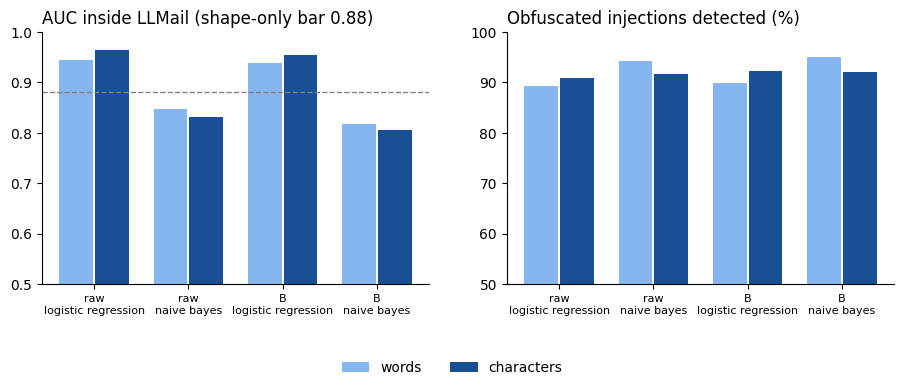

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
groups = [(v, m) for v in VARIANTS for m in MODELS]
labels = [f"{v.split()[0]}\n{m}" for v, m in groups]
x = np.arange(len(groups))
panels = [
    ("AUC LLMail only", lambda key: results.loc[key, "AUC LLMail only"], "AUC inside LLMail (shape-only bar 0.88)", (0.5, 1)),
    ("obfuscation", lambda key: rates.loc[key].iloc[1], "Obfuscated injections detected (%)", (50, 100)),
]
for ax, (_, value, title, limits) in zip(axes, panels):
    for i, (representation, color) in enumerate([("words", "#86b6ef"), ("characters", "#184f95")]):
        ax.bar(x + (i - 0.5) * 0.38, [value((v, representation, m)) for v, m in groups], width=0.36, color=color, label=representation)
    ax.set_xticks(x, labels, fontsize=8)
    ax.set_ylim(*limits)
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].axhline(0.88, color="grey", linestyle="--", linewidth=1)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=2, frameon=False)
fig.subplots_adjust(bottom=0.25)
plt.show()

- Obfuscated injections: characters help the logistic regression only a little (89.9 → 92.2 % on B).
- They also cut its false alarms on LLMail normal emails (20.7 → 15.8 % raw, 22.3 → 19.5 % B).
- Naive Bayes flags 45 to 63 % of the LLMail normal emails: it is not usable as a detector.

## The "confirmation" test

Same test as notebook 5, on the raw text: we delete "confirmation" from the test emails that contain it, and predict again.

In [7]:
with_word = test["has_confirmation"].to_numpy()
without_word = test.loc[with_word, "text"].str.replace(r"(?i)confirmation", "", regex=True)
groups_with_word = test.loc[with_word, "group"].to_numpy()

table = []
for representation in ["words", "characters"]:
    for name in MODELS:
        vectorizer, model = fitted["raw", representation, name]
        if representation == "words":
            X = vectorizer.transform(without_word)
        else:
            hashing, tfidf = vectorizer
            X = tfidf.transform(hashing.transform(without_word))
        before = probas["raw", representation, name][with_word] >= 0.5
        after = model.predict_proba(X)[:, 1] >= 0.5
        for group in ["injection", "llmail normal"]:
            g = groups_with_word == group
            table.append({
                "representation": representation, "model": name, "group": group, "emails": g.sum(),
                "flagged with the word (%)": before[g].mean() * 100,
                "flagged without it (%)": after[g].mean() * 100,
            })
pd.DataFrame(table).set_index(["representation", "model", "group"]).round(1)

emails  \
representation model               group                   
words          logistic regression injection        4914   
                                   llmail normal     875   
               naive bayes         injection        4914   
                                   llmail normal     875   
characters     logistic regression injection        4914   
                                   llmail normal     875   
               naive bayes         injection        4914   
                                   llmail normal     875   

                                                  flagged with the word (%)  \
representation model               group                                      
words          logistic regression injection                           95.0   
                                   llmail normal                       27.4   
               naive bayes         injection                           95.3   
                                   llmail normal                       45.3   
characters     logistic regression injection                           96.6   
                                   llmail normal                       24.5   
               naive bayes         injection                           93.4   
                                   llmail normal                       47.1   

                                                  flagged without it (%)  
representation model               group                                  
words          logistic regression injection                        92.5  
                                   llmail normal                    23.8  
               naive bayes         injection                        95.1  
                                   llmail normal                    44.3  
characters     logistic regression injection                        92.4  
                                   llmail normal                    13.4  
               naive bayes         injection                        92.3  
                                   llmail normal                    44.5

On raw text the character model depends more on the word than the word model: without it, its detection drops from 96.6 to 92.4 % and its false alarms from 24.5 to 13.4 %. Pieces like `con` or `ion` are in both "confirmation" and "contact", so the shortcut fills many columns. B matters even more with characters.

## Which pieces the logistic regression uses

As in notebook 5, columns are ranked by coefficient × standard deviation. A hashed column has no name: we show the two most frequent pieces that fall in it, over 2 000 training emails (`␣` is a space).

In [8]:
def pieces_by_column(column, n_emails=2000):
    """For each hashed column, its two most frequent pieces in a sample of training emails."""
    counts = Counter(piece for text in train[column].sample(n_emails, random_state=42) for piece in set(analyzer(text)))
    table = pd.DataFrame({"piece": list(counts), "emails": list(counts.values())})
    table["column"] = column_of(table["piece"].tolist())
    table["piece"] = table["piece"].str.replace(" ", "␣")
    return table.sort_values("emails", ascending=False).groupby("column")["piece"].agg(lambda s: "  /  ".join(s.head(2)))


tops = {}
for variant, column in VARIANTS.items():
    _, lr = fitted[variant, "characters", "logistic regression"]
    names = pieces_by_column(column)
    effect = pd.Series(lr.coef_[0] * stds[variant]).sort_values()
    tops[variant, "towards injection"] = [names.get(c, "?") for c in effect.tail(12).index[::-1]]
    tops[variant, "towards normal"] = [names.get(c, "?") for c in effect.head(12).index]
pd.DataFrame(tops)

raw                   B no shortcuts               
   towards injection towards normal towards injection towards normal
0       con  /  ␣obr   ____  /  332               ␣*␣    ␣/␣  /  ddo
1        ion  /  fse   ___  /  n␣Dr               ␣"␣            ␣:␣
2                act  ****  /  ␣d␣o      nd␣  /  ыть␣           _␣_␣
3      ntac  /  d`).   on␣  /  te␣y      ␣`␣  /  13␣c           *␣*␣
4               tact    ...  /  Obv              send            _␣_
5       onta  /  u>␣   l:␣R  /  Е␣О      end␣  /  br3           ␣_␣_
6                nta            ␣th               ␣'␣            ␣.␣
7      cont  /  b/in  or␣  /  H\tQ~     ␣sen  /  osa␣           ␣*␣*
8                tac   ␣-␣  /  setu               end   *␣*  /  ␣{␣y
9                ont            ***               sen            >␣<
10       tio  /  ำหร   |><  /  soc@       ion  /  fse  ␣>␣<  /  ␣c0r
11       nd␣  /  E␣#   NUM  /  rfee               mai  >␣<␣  /  heur

- Raw text, towards injection: almost only pieces of `contact` and `confirmation`. The model mostly detects the challenge's target.
- B, towards injection: pieces of `send` and `mail`, and symbols (`*`, `"`, `` ` ``) that attackers use to format their instructions.
- Towards normal: Enron separators (`____`, `...`), `NUM` (frequent in LLMail normal texts) and pieces of fake chat markers (`> <`).
- Some columns mix unrelated pieces (Cyrillic, Thai): the price of hashing.

## Conclusion

- Characters + logistic regression is the best model so far: AUC 0.986 on raw text, 0.981 on B.
- Small gain on obfuscated injections: pieces help with split words, not with leetspeak or swapped letters.
- On raw text, characters lean even more on the challenge's target: B is the fairer text from now on.
- Naive Bayes is not usable here.
- Next (step 7): LSA and Word2Vec, then SVM and XGBoost.